In [3]:
import numpy as np
import h2py
import moments 
import matplotlib.pyplot as plt 
import matplotlib as mpl
import copy
import msprime
import demes 
import demesdraw
import pandas
import pickle
from matplotlib.transforms import ScaledTranslation


mpl.rc("xtick", labelsize=7)
mpl.rc("ytick", labelsize=7)
mpl.rc("font", size=8)
mpl.rc("axes", labelsize=8)
mpl.rc("axes", titlesize=8)
mpl.rc("legend", fontsize=7)
mpl.rc("axes", titlesize="small")

In [59]:
# Load observed H2 quantiles from simulations in ../figure_simulations

distr = []
for rep in range(200):
    with open(f"../figure_simulations/results/equilibrium_rep_{rep}.pkl", "rb") as fin:
        data = pickle.load(fin)
    pop_data = np.array(data["means"])
    sig_h2 = pop_data[:-1, 0] / pop_data[-1, 0] ** 2
    distr.append(sig_h2)
eq_lower = np.quantile(distr, 0.025, axis=0)
eq_upper = np.quantile(distr, 0.975, axis=0)

distr = []
for rep in range(200):
    with open(f"../figure_simulations/results/growth_2_rep_{rep}.pkl", "rb") as fin:
        data = pickle.load(fin)
    pop_data = np.array(data["means"])
    sig_h2 = pop_data[:-1, 0] / pop_data[-1, 0] ** 2
    distr.append(sig_h2)
grow2_lower = np.quantile(distr, 0.025, axis=0)
grow2_upper = np.quantile(distr, 0.975, axis=0)

distr = []
for rep in range(200):
    with open(f"../figure_simulations/results/growth_50_rep_{rep}.pkl", "rb") as fin:
        data = pickle.load(fin)
    pop_data = np.array(data["means"])
    sig_h2 = pop_data[:-1, 0] / pop_data[-1, 0] ** 2
    distr.append(sig_h2)
grow50_lower = np.quantile(distr, 0.025, axis=0)
grow50_upper = np.quantile(distr, 0.975, axis=0)



distr = []
for rep in range(200):
    with open(f"../figure_simulations/results/shrink_0.2_rep_{rep}.pkl", "rb") as fin:
        data = pickle.load(fin)
    pop_data = np.array(data["means"])
    sig_h2 = pop_data[:-1, 0] / pop_data[-1, 0] ** 2
    distr.append(sig_h2)
shrink02_lower = np.quantile(distr, 0.025, axis=0)
shrink02_upper = np.quantile(distr, 0.975, axis=0)

distr = []
for rep in range(200):
    with open(f"../figure_simulations/results/shrink_5_rep_{rep}.pkl", "rb") as fin:
        data = pickle.load(fin)
    pop_data = np.array(data["means"])
    sig_h2 = pop_data[:-1, 0] / pop_data[-1, 0] ** 2
    distr.append(sig_h2)
shrink5_lower = np.quantile(distr, 0.025, axis=0)
shrink5_upper = np.quantile(distr, 0.975, axis=0)


distr = []
for rep in range(200):
    with open(f"../figure_simulations/results/isolation_0_rep_{rep}.pkl", "rb") as fin:
        data = pickle.load(fin)
    pop_data = np.array(data["means"])
    sig_h2 = pop_data[:-1, 1] / pop_data[-1, 1] ** 2
    distr.append(sig_h2)
div0_lower = np.quantile(distr, 0.025, axis=0)
div0_upper = np.quantile(distr, 0.975, axis=0)

distr = []
for rep in range(200):
    with open(f"../figure_simulations/results/isolation_1_rep_{rep}.pkl", "rb") as fin:
        data = pickle.load(fin)
    pop_data = np.array(data["means"])
    sig_h2 = pop_data[:-1, 1] / pop_data[-1, 1] ** 2
    distr.append(sig_h2)
div1_lower = np.quantile(distr, 0.025, axis=0)
div1_upper = np.quantile(distr, 0.975, axis=0)

distr = []
for rep in range(200):
    with open(f"../figure_simulations/results/isolation_4_rep_{rep}.pkl", "rb") as fin:
        data = pickle.load(fin)
    pop_data = np.array(data["means"])
    sig_h2 = pop_data[:-1, 1] / pop_data[-1, 1] ** 2
    distr.append(sig_h2)
div4_lower = np.quantile(distr, 0.025, axis=0)
div4_upper = np.quantile(distr, 0.975, axis=0)



distr = []
for rep in range(200):
    # simulations are mislabelled
    with open(f"../figure_simulations/results/admixture_2_0.05_rep_{rep}.pkl", "rb") as fin:
        data = pickle.load(fin)
    pop_data = np.array(data["means"])
    sig_h2 = pop_data[:-1, 0] / pop_data[-1, 0] ** 2
    distr.append(sig_h2)
pulse1_lower = np.quantile(distr, 0.025, axis=0)
pulse1_upper = np.quantile(distr, 0.975, axis=0)

distr = []
for rep in range(200):
    with open(f"../figure_simulations/results/admixture_4_0.05_rep_{rep}.pkl", "rb") as fin:
        data = pickle.load(fin)
    pop_data = np.array(data["means"])
    sig_h2 = pop_data[:-1, 0] / pop_data[-1, 0] ** 2
    distr.append(sig_h2)
pulse4_lower = np.quantile(distr, 0.025, axis=0)
pulse4_upper = np.quantile(distr, 0.975, axis=0)


bins = np.logspace(-6, -2, 17)
bin_mids = (bins[1:] + bins[:-1]) / 2

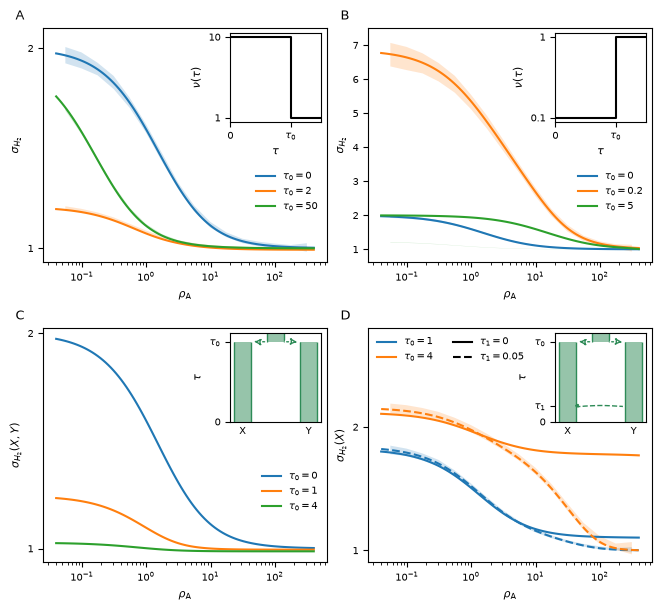

In [60]:
"""
create Figure 1, the main theory figure.
"""


graph_color = "seagreen"
inset_coords = [0.66, 0.60, 0.32, 0.38]
text_x = 4e-2
N = 1e4
u = 1e-8
theta = 4 * N * u
rs = np.logspace(np.log10(1e-6), np.log10(1e-2), 100)
rhos = 4 * N * rs


def make_covariance_plot(ax):
    # plot the genealogical covariance Cov(Tl, Tr) at equilibrium
    covs = (rhos + 18) / (rhos ** 2 + 13 * rhos + 18)
    ax.plot(rhos, covs, color="black")
    ax.set_xscale("log")
    ax.set_ylabel(r"$\operatorname{Cov}(T_L, T_R)$")
    ax.set_xlabel(r"$\rho$")
    ax.set_yticks([0, 1])
    ax.set_ylim(0, )
    return


def make_equil_expectation_plot(ax):
    yy = moments.LD.Demographics1D.snm(rho=rhos, theta=theta)
    dp = yy.H2(0)
    ax.plot(rhos, dp, color="black")
    ax.set_xscale("log")
    ax.set_ylabel(r"$E[H_2]$")
    ax.set_xlabel(r"$\rho$")
    ax.set_yticks([theta ** 2, 2 * theta ** 2], [r"$\theta^2$", r"$2\theta^2$"])
    return


def make_growth_plot(ax):
    inset = ax.inset_axes(inset_coords)
    inset.step([0, 1, 1.5], [10, 10, 1], color="black")
    inset.set_xticks([1, 0], [r"$\tau_0$", 0])
    inset.set_ylabel(r"$\nu(\tau)$")
    inset.set_xlabel(r"$\tau$")
    inset.set_xlim(0, 1.5)
    inset.set_yscale("log")
    inset.set_yticks([1, 10], [1, 10])
    inset.minorticks_off()

    # simulations
    rho_mids = bin_mids * 4 * 1e4
    ax.fill_between(rho_mids, eq_lower, eq_upper, color="tab:blue", alpha=0.2, edgecolor="none")
    
    ax.fill_between(rho_mids, grow2_lower, grow2_upper, color="tab:orange", alpha=0.2, edgecolor="none")
    
    ax.fill_between(rho_mids, grow50_lower, grow50_upper, color="tab:green", alpha=0.2, edgecolor="none")

    
    yy0 = moments.LD.Demographics1D.snm(rho=rhos, theta=theta)
    dp0 = yy0.H2(0)
    ax.plot(rhos, dp0 / yy0.H() ** 2, color="tab:blue", label=r"$\tau_0=0$")

    yy = moments.LD.Demographics1D.two_epoch([10, 2], rho=rhos, theta=theta)
    dp = yy.H2(0)
    ax.plot(rhos, dp / yy.H() ** 2, color="tab:orange", label=r"$\tau_0=2$")

    yy = moments.LD.Demographics1D.two_epoch([10, 50], rho=rhos, theta=theta)
    dp = yy.H2(0)
    ax.plot(rhos, dp / yy.H() ** 2, color="tab:green", label=r"$\tau_0=50$")
    
    ax.legend(framealpha=0, loc="center right", bbox_to_anchor=(1, 0.3))

    #ax.annotate(r"$\tau=0$", (text_x, 2), color="tab:blue")
    #ax.annotate(r"$\tau=2$", (text_x, 1.23), color="tab:orange")
    #ax.annotate(r"$\tau=\infty$", (text_x, 1.81), color="tab:green")
    ax.set_xscale("log")
    ax.set_ylabel(r"$\sigma_{H_2}$")
    ax.set_xlabel(r"$\rho_\text{A}$")
    ax.set_yticks([1, 2])
    ax.set_ylim(None, 2.1)
    return


def make_contraction_plot(ax):
    inset = ax.inset_axes(inset_coords)
    inset.step([0, 1, 1.5], [0.1, 0.1, 1], color="black", label="growth")
    inset.set_xticks([1, 0], [r"$\tau_0$", 0])
    inset.set_ylabel(r"$\nu(\tau)$")
    inset.set_xlabel(r"$\tau$")
    inset.set_xlim(0, 1.5)
    inset.set_yscale("log")
    inset.set_yticks([0.1, 1], [0.1, 1])
    inset.minorticks_off()

    
    # simulations
    rho_mids = bin_mids * 4 * 1e4
    ax.fill_between(rho_mids, eq_lower, eq_upper, color="tab:blue", alpha=0.2, edgecolor="none")
    
    ax.fill_between(rho_mids, shrink02_lower, shrink02_upper, color="tab:orange", alpha=0.2, edgecolor="none")
    
    ax.fill_between(rho_mids, shrink5_lower, shrink5_upper, color="tab:green", alpha=0.2, edgecolor="none")
    

    yy0 = moments.LD.Demographics1D.snm(rho=rhos, theta=theta)
    dp0 = yy0.H2(0)
    ax.plot(rhos, dp0 / yy0.H() ** 2, color="tab:blue", label=r"$\tau_0=0$")

    yy = moments.LD.Demographics1D.two_epoch([0.1, 0.2], rho=rhos, theta=theta)
    dp = yy.H2(0)
    ax.plot(rhos, dp / yy.H() ** 2, color="tab:orange", label=r"$\tau_0=0.2$")

    yy = moments.LD.Demographics1D.two_epoch([0.1, 5], rho=rhos, theta=theta)
    dp = yy.H2(0)
    ax.plot(rhos, dp / yy.H() ** 2, color="tab:green", label=r"$\tau_0=5$")

    ax.legend(framealpha=0, loc="center right", bbox_to_anchor=(1, 0.3))

    #ax.annotate(r"$\tau=0$", (text_x, 1.4), color="tab:blue")
    #ax.annotate(r"$\tau=0.2$", (text_x, 6.95), color="tab:orange")
    #ax.annotate(r"$\tau=\infty$", (text_x, 2.31), color="tab:green")

    ax.set_xscale("log")
    ax.set_ylabel(r"$\sigma_{H_2}$")
    ax.set_xlabel(r"$\rho_\text{A}$")
    ax.set_ylim(None, 7.5)
    return


def make_island_plot(ax):
    inset = ax.inset_axes(inset_coords)
    builder = demes.Builder()
    builder.add_deme("A", epochs=[{"start_size": 1000, "end_time": 0}])
    builder.add_deme("B", epochs=[{"start_size": 1000, "end_time": 0}])
    builder.add_migration(rate=1e-4, demes=["A", "B"])
    graph = builder.resolve()
    demesdraw.tubes(graph, ax=inset, colours=graph_color, labels=None, 
                    num_lines_per_migration=4, positions={"A": 0, "B": 2e3})
    inset.spines["top"].set_visible(True)
    inset.spines["right"].set_visible(True)
    inset.spines["bottom"].set_visible(True)
    inset.set_ylabel(r"$\tau$")
    inset.set_yticks([0])

    yy = moments.LD.Demographics2D.island_model([0.5, 0.5, 0.5, 0.5], rho=rhos, theta=theta)
    ax.plot(rhos, yy.H2(0) / yy.H()[0] ** 2, color="tab:blue")
    ax.annotate("$M=1$", (text_x, 2.6), color="tab:blue")

    yy = moments.LD.Demographics2D.island_model([0.5, 0.5, 2.5, 2.5], rho=rhos, theta=theta)
    ax.plot(rhos, yy.H2(0) / yy.H()[0] ** 2, color="tab:orange")
    ax.annotate("$M=5$", (text_x, 2.25), color="tab:orange")

    yy = moments.LD.Demographics2D.island_model([0.5, 0.5, 50, 50], rho=rhos, theta=theta)
    ax.plot(rhos, yy.H2(0) / yy.H()[0] ** 2, color="tab:green")
    ax.annotate("$M=100$", (text_x, 1.6), color="tab:green")


    ax.set_xscale("log")
    ax.set_ylabel(r"$\sigma_{H_2}$")
    ax.set_xlabel(r"$\rho_\text{A}$")
    ax.set_yticks([1, 2, 3])
    return


def get_isolation_model(T):
    builder = demes.Builder()
    builder.add_deme("A", epochs=[{"start_size": 1e4, "end_time": T}])
    builder.add_deme(
        "X", ancestors=["A"], epochs=[{"start_size": 1e4, "end_time": 0}])
    builder.add_deme(
        "Y", ancestors=["A"], epochs=[{"start_size": 1e4, "end_time": 0}])
    graph = builder.resolve()
    return graph


def make_isolation_plot(ax):
    inset = ax.inset_axes(inset_coords)
    plot_isolation_model(inset)

    # simulations
    rho_mids = bin_mids * 4 * 1e4
    #ax.fill_between(rho_mids, div0_lower, div0_upper, color="tab:blue", alpha=0.2, edgecolor="none")
    
    #ax.fill_between(rho_mids, div1_lower, div1_upper, color="tab:orange", alpha=0.2, edgecolor="none")
    
    #ax.fill_between(rho_mids, div4_lower, div4_upper, color="tab:green", alpha=0.2, edgecolor="none")
    
    yy = moments.Demes.LD(
        get_isolation_model(1), sampled_demes=["X", "Y"], u=u, r=rs)
    dp = yy.H2(0, 1, phased=True)
    ax.plot(rhos, dp / yy.H()[1] ** 2, color="tab:blue", label=r"$\tau_0=0$")

    yy = moments.Demes.LD(
        get_isolation_model(2e4), sampled_demes=["X", "Y"], u=u, r=rs)
    dp = yy.H2(0, 1, phased=True)
    ax.plot(rhos, dp / yy.H()[1] ** 2, color="tab:orange", label=r"$\tau_0=1$")

    yy = moments.Demes.LD(
        get_isolation_model(8e4), sampled_demes=["X", "Y"], u=u, r=rs)
    dp = yy.H2(0, 1, phased=True)
    ax.plot(rhos, dp / yy.H()[1] ** 2, color="tab:green", label=r"$\tau_0=4$")
    
    ax.legend(framealpha=0, loc="center right", bbox_to_anchor=(1, 0.3))

    #ax.annotate(r"$\tau_0=0$", (text_x, 1.48), color="tab:blue")
    #ax.annotate(r"$\tau_0=1$", (text_x, 1.2), color="tab:orange")
    #ax.annotate(r"$\tau_0=4$", (text_x, 1.04), color="tab:green")

    ax.set_xscale("log")
    ax.set_ylabel(r"$\sigma_{H_2}(X,Y)$")
    ax.set_xlabel(r"$\rho_\text{A}$")
    ax.set_yticks([1, 2])
    # ax.set_ylim(None, 1.52)
    return



def plot_isolation_model(ax):
    
    graph = get_isolation_model(2e4)
    demesdraw.tubes(graph, ax=ax, labels="xticks", colours=graph_color, 
                    inf_ratio=0.10, positions={"A": 0, "X": -2e4, "Y": 2e4})
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    ax.set_ylabel(r"$\tau$")
    ax.set_yticks([0, 2e4], [0, r"$\tau_0$"])



def label_axs(fig, axs):
    # label axs in mosaic subplots 
    for label, ax in axs.items():
        ax.text(0.0, 1.0, label, fontsize="large", va="bottom", transform=(
            ax.transAxes + ScaledTranslation(-20/72, 4/72, fig.dpi_scale_trans)))
    return    



def make_introgression_plot(ax):
    inset = ax.inset_axes(inset_coords)
    plot_introgression_model(inset)
    #yy = moments.Demes.LD(
    #    get_introgression_model(0.0, 2e4, 1), sampled_demes=["X"], u=u, r=rs)
    #dp = yy.H2(0)
    #ax.plot(rhos, dp / yy.H() ** 2, color="tab:blue", label=r"$\gamma=0$")

    # simulation
    rho_mids = bin_mids * 4 * 1e4
    ax.fill_between(rho_mids, pulse1_lower, pulse1_upper, color="tab:blue", alpha=0.2, edgecolor="none")
    
    ax.fill_between(rho_mids, pulse4_lower, pulse4_upper, color="tab:orange", alpha=0.2, edgecolor="none")

    
    yy = moments.Demes.LD(
        get_introgression_model(0.10, 2e4, 1), sampled_demes=["X"], u=u, r=rs)
    dp = yy.H2(0)
    ax.plot(rhos, dp / yy.H() ** 2, color="tab:blue", label=r"$\tau_0=1$")
    yy = moments.Demes.LD(
        get_introgression_model(0.10, 2e4 + 1000, 1000), sampled_demes=["X"], u=u, r=rs)
    dp = yy.H2(0)
    ax.plot(rhos, dp / yy.H() ** 2, "--", color="tab:blue")

    yy = moments.Demes.LD(
        get_introgression_model(0.10, 8e4, 1), sampled_demes=["X"], u=u, r=rs)
    dp = yy.H2(0)
    ax.plot(rhos, dp / yy.H() ** 2, color="tab:orange", label=r"$\tau_0=4$")
    yy = moments.Demes.LD(
        get_introgression_model(0.10, 8e4 + 1000, 1000), sampled_demes=["X"], u=u, r=rs)
    dp = yy.H2(0)
    ax.plot(rhos, dp / yy.H() ** 2, "--", color="tab:orange")

    ax.plot([], [], "-", color="black", label="$\\tau_1=0$")
    ax.plot([], [], "--", color="black", label="$\\tau_1=0.05$")
    
    # ax.annotate(r"$\gamma=0$", (text_x, 1.55), color="tab:blue")
    # ax.annotate(r"$\tau_0=1$", (text_x, 1.4), color="tab:orange")
    # ax.annotate(r"$\tau_0=4$", (text_x, 2.2), color="tab:green")
    ax.legend(framealpha=0, loc="upper left", ncols=2)
    ax.set_xscale("log")
    ax.set_ylabel(r"$\sigma_{H_2}(X)$")
    ax.set_xlabel(r"$\rho_\text{A}$")
    ax.set_yticks([1, 2])
    ax.set_ylim(None, 2.8)
    return


def get_introgression_model(p, t0, t1):
    builder = demes.Builder()
    builder.add_deme("A", epochs=[{"start_size": 1e4, "end_time": t0}])
    builder.add_deme(
        "X", ancestors=["A"], epochs=[{"start_size": 1e4, "end_time": 0}])
    builder.add_deme(
        "Y", ancestors=["A"], epochs=[{"start_size": 1e4, "end_time": 0}])
    builder.add_pulse(sources=["Y"], dest="X", time=t1, proportions=[p])
    graph = builder.resolve()
    return graph


def plot_introgression_model(ax):
    
    graph = get_introgression_model(0.10, 2.5e4, 5e3)
    demesdraw.tubes(graph, ax=ax, labels="xticks", colours=graph_color, 
                    inf_ratio=0.10, positions={"A": 0, "X": -2e4, "Y": 2e4})
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    ax.set_ylabel(r"$\tau$")
    ax.set_yticks([0, 5000, 25000], [0, r"$\tau_1$", r"$\tau_0$"])
    

mosaic = "AB;CD"
fig, axs = plt.subplot_mosaic(mosaic, figsize=(6.5, 6), layout="constrained")
label_axs(fig, axs)
#make_covariance_plot(axs["A"])
#make_equil_expectation_plot(axs["B"])
#make_growth_plot(axs["C"])
#make_contraction_plot(axs["D"])
#make_isolation_plot(axs["E"])
#make_introgression_plot(axs["F"])
make_growth_plot(axs["A"])
make_contraction_plot(axs["B"])
make_isolation_plot(axs["C"])
make_introgression_plot(axs["D"])
plt.savefig("../../figures/theory.pdf")

In [3]:
"""
precomputation for Figure 2.
sets up three models with structured ancestry and finds panmictic models
with equivalent coalescence rate profiles.
"""


def get_structure_model(params):
    N0, N1, N2, T0, T1, p, m = params
    builder = demes.Builder()
    builder.add_deme("Anc", epochs=[{"start_size": N0, "end_time": T0}])
    builder.add_deme("X", ancestors=["Anc"], 
                     epochs=[{"start_size": N1, "end_time": T1}])
    builder.add_deme("Y", ancestors=["Anc"], 
                     epochs=[{"start_size": N2, "end_time": T1}])
    builder.add_deme("A", ancestors=["X", "Y"], proportions=[p, 1-p],
                     start_time=T1, 
                     epochs=[{"start_size": N0, "end_time": 0}])
    builder.add_migration(rate=m, demes=["X", "Y"])
    graph = builder.resolve()
    return graph


def compute_rate_trajectory(graph, ts, sample):
    demog = msprime.Demography.from_demes(graph)
    debug = demog.debug()
    rates, _ = debug.coalescence_rate_trajectory(ts, {sample: 2})
    return rates


def get_panmictic_model(ts, rates):
    Nes = 1 / (2 * np.array(rates))
    _ts = np.flip(ts)
    _Nes = np.flip(Nes)
    epochs = [
        {"start_size": Ne, "end_time": t} for Ne, t in zip(_Nes, _ts)
    ]
    builder = demes.Builder()
    builder.add_deme("A", epochs=epochs)
    graph = builder.resolve()
    return graph


# M = 0
ts = np.linspace(0, 2.5e4, 301)
structure_model0 = get_structure_model([1e4, 5e3, 5e3, 2.2e4, 2e3, 0.50, 0])
rates0 = compute_rate_trajectory(structure_model0, ts, "A")
panmictic_model0 = get_panmictic_model(ts, rates0)

# M = 0.5
structure_model1 = get_structure_model([1e4, 5e3, 5e3, 2.2e4, 2e3, 0.50, 0.5 / (4 * 5e3)])
rates1 = compute_rate_trajectory(structure_model1, ts, "A")
panmictic_model1 = get_panmictic_model(ts, rates1)

# M = 1
structure_model2 = get_structure_model([1e4, 5e3, 5e3, 2.2e4, 2e3, 0.50, 1 / (4 * 5e3)])
rates2 = compute_rate_trajectory(structure_model2, ts, "A")
panmictic_model2 = get_panmictic_model(ts, rates2)


rs = np.logspace(-6, -2, 31)
u = 1.3e-8
struc_yy0 = moments.Demes.LD(structure_model0, sampled_demes=["A"], r=rs, u=u)
struc_yy1 = moments.Demes.LD(structure_model1, sampled_demes=["A"], r=rs, u=u)
struc_yy2 = moments.Demes.LD(structure_model2, sampled_demes=["A"], r=rs, u=u)
pan_yy0 = moments.Demes.LD(panmictic_model0, sampled_demes=["A"], r=rs, u=u)
pan_yy1 = moments.Demes.LD(panmictic_model1, sampled_demes=["A"], r=rs, u=u)
pan_yy2 = moments.Demes.LD(panmictic_model2, sampled_demes=["A"], r=rs, u=u)

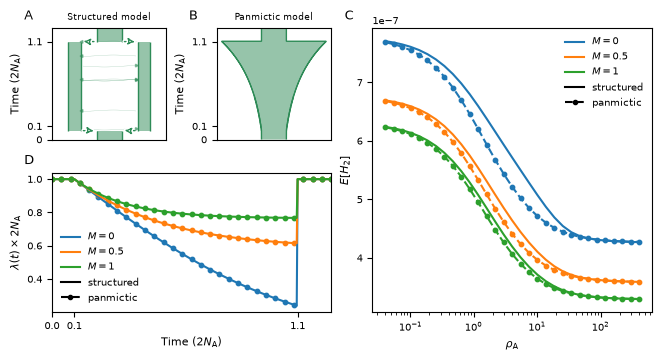

In [4]:



def make_coal_rate_plot(ax):
    xs = ts / 2e4
    ax.plot(xs, rates0 * 2e4, color="tab:blue", label="$M=0$")
    ax.plot(xs, rates1 * 2e4, color="tab:orange", label="$M=0.5$")
    ax.plot(xs, rates2 * 2e4, color="tab:green", label="$M=1$")

    _ts = np.linspace(0, 2.5e4, 31)
    pan_rates0 = compute_rate_trajectory(panmictic_model0, _ts, "A") * 2e4
    pan_rates1 = compute_rate_trajectory(panmictic_model1, _ts, "A") * 2e4
    pan_rates2 = compute_rate_trajectory(panmictic_model2, _ts, "A") * 2e4
    _xs = _ts / 2e4
    ax.scatter(_xs, pan_rates0, color="tab:blue", s=10)
    ax.scatter(_xs, pan_rates1, color="tab:orange", s=10)
    ax.scatter(_xs, pan_rates2, color="tab:green", s=10)
    ax.set_xlabel(r"Time ($2N_\text{A}$)")
    ax.set_ylabel(r"$\lambda(t) \times 2N_\text{A}$")
    ax.plot([], [], color="black", label="structured")
    ax.plot([], [], "--o", color="black", label="panmictic", markersize=3)
    ax.legend(framealpha=0, ncols=1, loc="best")
    ax.set_xlim(0, )
    # ax.text(1.07, 0.35, "$M=0$", horizontalalignment="right", color="tab:blue", )
    # ax.text(1.07, 0.66, "$M=1$", horizontalalignment="right", color="tab:orange")
    # ax.text(1.07, 0.95, "$M=10$", horizontalalignment="right", color="tab:green")
    ax.set_xlim(0, xs[-1])
    ax.set_xticks([0, 0.1, 1.1])
    return


def plot_structure_model(ax):
    # plot demesdraw representation of the model
    plot_model = structure_model0
    demesdraw.tubes(
        plot_model, ax=ax, colours=graph_color, fill=True, labels=None,
        inf_ratio=0.4, positions={"Anc": 0, "X": -1.4e4, "Y": 1.4e4, "A": 0},
        num_lines_per_migration=4)
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    ax.set_ylabel(r"Time ($2N_\text{A}$)")
    ax.set_yticks([0, 5e3, 2.5e4], ["0", "$T_1$", "$T_0$"])
    ax.set_yticks([0, 3e3, 2.2e4], [0, 0.1, 1.1])
    ax.set_xlim(-2.3e4, 2.3e4)
    ax.set_ylim(0, 25000)
    return 


def plot_panmictic_model(ax):
    # plot demesdraw representation of the model
    ts = np.linspace(0, 2.5e4, 26)
    _rates0 = compute_rate_trajectory(structure_model0, ts, "A")
    plot_model = get_panmictic_model(ts, _rates0)
    demesdraw.tubes(
        plot_model, ax=ax, colours=graph_color, fill=True, labels=None,
        inf_ratio=0.4, num_lines_per_migration=4)
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    ax.set_ylabel(r"Time ($2N_\text{A}$)")
    ax.set_yticks([0, 5e3, 2.5e4], ["0", "$T_1$", "$T_0$"])
    ax.set_yticks([0, 3e3, 2.2e4], [0, 0.1, 1.1])
    ax.set_xlim(-2.3e4, 2.3e4)
    ax.set_ylim(0, 25000)
    return 


def make_curves_plot(ax):
    rs = np.logspace(-6, -2, 31)
    rhos = 4 * 1e4 * rs
    ax.plot(rhos, struc_yy0.H2(0), color="tab:blue", label="$M=0$")
    ax.plot(rhos, struc_yy1.H2(0), color="tab:orange", label="$M=0.5$")
    ax.plot(rhos, struc_yy2.H2(0), color="tab:green", label="$M=1$")

    ax.plot(rhos, pan_yy0.H2(0), "--", color="tab:blue")
    ax.plot(rhos, pan_yy1.H2(0), "--", color="tab:orange")
    ax.plot(rhos, pan_yy2.H2(0), "--", color="tab:green")
    ax.scatter(rhos, pan_yy0.H2(0), color="tab:blue", s=10)
    ax.scatter(rhos, pan_yy1.H2(0), color="tab:orange", s=10)
    ax.scatter(rhos, pan_yy2.H2(0), color="tab:green", s=10)
    ax.set_xscale("log")
    ax.set_ylabel(r"$E[H_2]$")
    ax.set_xlabel(r"$\rho_\text{A}$")
    ax.plot([], [], color="black", label="structured")
    ax.plot([], [], "--o", color="black", label="panmictic", markersize=3)
    ax.legend(framealpha=0, ncols=1)
    return

def make_introgression_model_plot(ax):
    graph = get_introgression_model(0.10, 500)
    demesdraw.tubes(graph, ax=ax, labels="xticks", fill=True, colours=graph_color)
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    ax.set_ylabel("$t$ (generations ago)")
    return


def plot_structure_model(ax):
    # plot demesdraw representation of the model
    plot_model = structure_model0
    demesdraw.tubes(
        plot_model, ax=ax, colours=graph_color, fill=True, labels=None,
        inf_ratio=0.4, positions={"Anc": 0, "X": -1.4e4, "Y": 1.4e4, "A": 0},
        num_lines_per_migration=4)
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    ax.set_ylabel(r"Time ($2N_\text{A}$)")
    ax.set_yticks([0, 5e3, 2.5e4], ["0", "$T_1$", "$T_0$"])
    ax.set_yticks([0, 3e3, 2.2e4], [0, 0.1, 1.1])
    ax.set_xlim(-2.3e4, 2.3e4)
    ax.set_ylim(0, 25000)
    return 


def plot_panmictic_model(ax):
    # plot demesdraw representation of the model
    ts = np.linspace(0, 2.5e4, 300)
    _rates0 = compute_rate_trajectory(structure_model0, ts, "A")
    plot_model = get_panmictic_model(ts, _rates0)
    demesdraw.tubes(
        plot_model, ax=ax, colours=graph_color, fill=True, labels=None,
        inf_ratio=0.4, num_lines_per_migration=4)
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    ax.set_ylabel(r"Time ($2N_\text{A}$)")
    ax.set_yticks([0, 5e3, 2.5e4], ["0", "$T_1$", "$T_0$"])
    ax.set_yticks([0, 3e3, 2.2e4], [0, 0.1, 1.1])
    ax.set_xlim(-2.3e4, 2.3e4)
    ax.set_ylim(0, 25000)
    return 




mosaic = "ABCC;DDCC"
fig, axs = plt.subplot_mosaic(mosaic, figsize=(6.5, 3.5), layout="constrained", height_ratios=[1, 1.25])
label_axs(fig, axs)
plot_structure_model(axs["A"])
axs["A"].set_title("Structured model")
plot_panmictic_model(axs["B"])
axs["B"].set_title("Panmictic model")
make_curves_plot(axs["C"])
make_coal_rate_plot(axs["D"])
plt.savefig("../../figures/structure_theory.pdf")